<a href="https://colab.research.google.com/github/elvissoares/EQE595-SimMol/blob/main/notebooks/6_OpenMM_e_Agua.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula Prática 06 - Dinâmica Molecular da Água usando OpenMM

Autor: [Prof. Elvis do A. Soares](https://github.com/elvissoares)

Contato: [elvis@peq.coppe.ufrj.br](mailto:elvis@peq.coppe.ufrj.br) - [Programa de Engenharia Química, PEQ/COPPE, UFRJ, Brasil](https://www.peq.coppe.ufrj.br/)

---

## 🎯 Objetivos da aula

Ao final desta aula você deverá ser capaz de:

1. Reconhecer no OpenMM as mesmas peças que você já programou à mão (forças, integrador, condições periódicas);
2. Entender o que é um **campo de força** e inspecionar os parâmetros do modelo de água **TIP3P**;
3. Entender por que o **passo de tempo** depende das vibrações mais rápidas da molécula;
4. Montar uma caixa com 1000 moléculas de água e simulá-la nos ensembles **NVT** e **NPT**;
5. Calcular a densidade da água **com a incerteza correta** e comparar com dados experimentais;
6. Extrair propriedades termodinâmicas (compressibilidade, entalpia de vaporização) e estruturais ($g(r)$) da simulação.

## 🗺️ Roteiro

| Parte | O que fazemos | Custo computacional |
|---|---|---|
| 0 | Instalação, unidades e plataforma | ~1 min |
| 1 | **Uma** molécula: topologia, campo de força, energia, vibração | segundos |
| 2 | Caixa com 1000 moléculas: equilibração NVT → produção NPT | poucos minutos (GPU) |
| 3 | Análise: densidade, incerteza, flutuações, $g(r)$ | segundos |
| 4 | Hands-on | variável |

## 🔗 Do seu código em Python para o OpenMM

Nas aulas anteriores vocês escreveram, do zero, uma dinâmica molecular de partículas de Lennard-Jones. O OpenMM faz **exatamente as mesmas coisas**, só que de forma genérica, otimizada e, se houver, na GPU:

| No seu código | No OpenMM |
|---|---|
| arrays com massas e tipos das partículas | `Topology`: quem é quem e quem está ligado a quem |
| função `forcas(r)` com o potencial LJ | `ForceField` → `System` (uma lista de objetos `Force`) |
| laço `for` com o Verlet ou o Langevin | `Integrator` (`VerletIntegrator`, `LangevinMiddleIntegrator`, ...) |
| condições periódicas e raio de corte | caixa periódica + `nonbondedMethod` e `nonbondedCutoff` |
| listas onde você guardava $E$, $T$, ... | *reporters* (`StateDataReporter`, `DCDReporter`) |
| NumPy rodando na CPU | `Platform` (CPU, CUDA, OpenCL) |

```
 Topology ───┐
             ├──► ForceField.createSystem() ──► System ──┐
 ForceField ─┘                                          ├──► Simulation ──► simulation.step(n)
                          Integrator + Platform ────────┘     (Context: posições, velocidades, caixa)
```

---
# Parte 0 — Preparando o ambiente

No Google Colab, ative a GPU em **Ambiente de execução → Alterar o tipo de ambiente de execução → GPU (T4)**. Depois instale o OpenMM e o MDTraj (biblioteca para analisar trajetórias):

In [ ]:
%%capture
!pip install openmm[cuda12] mdtraj

Testando a instalação e vendo quais *plataformas* (CPU, CUDA, OpenCL) estão disponíveis:

In [ ]:
!python -m openmm.testInstallation

Importações. Usaremos os três módulos do OpenMM com **nomes explícitos**, para ficar claro de onde vem cada coisa:

- `openmm` (`mm`): o núcleo — `System`, forças, integradores, plataformas;
- `openmm.app` (`app`): a camada de aplicação — `Topology`, `ForceField`, `Simulation`, *reporters*, leitura e escrita de PDB;
- `openmm.unit` (`unit`): o sistema de unidades.

In [ ]:
from sys import stdout
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math

import openmm as mm
import openmm.app as app
import openmm.unit as unit

print("OpenMM", mm.__version__)

## 0.1 Unidades no OpenMM ⚠️

Qualquer número no OpenMM pode carregar sua unidade (um objeto `Quantity`). Internamente o OpenMM usa **nm, ps, g/mol, kJ/mol e K**. Esse conjunto é consistente: como $1\ \text{kJ/mol} = 1\ (\text{g/mol})\,\text{nm}^2/\text{ps}^2$, a 2ª lei de Newton $F = m a$ funciona sem nenhum fator de conversão — a mesma ideia das unidades reduzidas que vocês usaram no Lennard-Jones.

In [ ]:
l0 = 0.9572 * unit.angstrom
print(l0)                                  # Quantity com unidade
print(l0.in_units_of(unit.nanometer))      # conversão de unidade
print(l0.value_in_unit(unit.nanometer))    # número puro (float), em nm
print(l0 / unit.nanometer)                 # o mesmo: dividir pela unidade dá um número puro

> 💡 **Regra de ouro:** só tire a unidade (`.value_in_unit(...)`) quando for fazer contas com NumPy, e faça **todas** essas contas na mesma unidade. Somar um número em Å com outro em nm é um erro silencioso: depois que tudo virou `float`, o OpenMM não tem como detectá-lo. Neste notebook, **todas as posições serão manipuladas em nm**.

## 0.2 Escolhendo a plataforma

A função abaixo tenta usar CUDA (GPU NVIDIA), depois OpenCL e, por último, a CPU. Assim o mesmo notebook roda no Colab com GPU, no Colab sem GPU ou no seu computador.

In [ ]:
def escolhe_plataforma(preferencias=("CUDA", "OpenCL", "CPU")):
    for nome in preferencias:
        try:
            plataforma = mm.Platform.getPlatformByName(nome)
            # teste rápido: cria um contexto com uma única partícula
            teste = mm.System()
            teste.addParticle(1.0)
            mm.Context(teste, mm.VerletIntegrator(0.001), plataforma)
            print(f"Usando a plataforma {nome}")
            return plataforma
        except Exception:
            print(f"Plataforma {nome} indisponível")
    raise RuntimeError("Nenhuma plataforma disponível")

plataforma = escolhe_plataforma()

---
# Parte 1 — Uma única molécula de água

Antes de simular mil moléculas, vamos olhar com lupa para **uma** molécula. É aqui que entendemos o que o campo de força faz.

## 1.1 Topologia

H2O_2D_labelled.svg

A **topologia** diz apenas *quais átomos existem* (elemento, nome, resíduo) e *quais estão ligados*. Ela **não** contém coordenadas nem parâmetros de interação.

In [ ]:
elemento_O = app.Element.getBySymbol("O")
elemento_H = app.Element.getBySymbol("H")

topologia_1mol = app.Topology()
cadeia = topologia_1mol.addChain()
residuo = topologia_1mol.addResidue("HOH", cadeia)   # HOH é o nome padrão de água em arquivos PDB
O  = topologia_1mol.addAtom("O",  elemento_O, residuo)
H1 = topologia_1mol.addAtom("H1", elemento_H, residuo)
H2 = topologia_1mol.addAtom("H2", elemento_H, residuo)
topologia_1mol.addBond(O, H1)
topologia_1mol.addBond(O, H2)

print(topologia_1mol)
for atomo in topologia_1mol.atoms():
    print(f"Átomo {atomo.index}: {atomo.name:2s}  massa = {atomo.element.mass}")

Uma função auxiliar para gerar as coordenadas da molécula (sempre em **nm**) a partir de dois comprimentos de ligação e do ângulo H–O–H. O oxigênio fica na origem, H1 sobre o eixo $x$ e H2 no plano $xy$:

In [ ]:
def geometria_agua(l1=0.09572, l2=0.09572, theta=np.deg2rad(104.52)):
    # Posições de O, H1 e H2 em nm (array 3x3)
    return np.array([
        [0.0,                0.0,                0.0],   # O
        [l1,                 0.0,                0.0],   # H1
        [l2 * np.cos(theta), l2 * np.sin(theta), 0.0],   # H2
    ])

def mede_geometria(pos):
    # Recebe posições (nm) de O, H1, H2 e retorna (l1, l2, theta em graus)
    d1, d2 = pos[1] - pos[0], pos[2] - pos[0]
    l1, l2 = np.linalg.norm(d1), np.linalg.norm(d2)
    theta = np.degrees(np.arccos(np.dot(d1, d2) / (l1 * l2)))
    return l1, l2, theta

print(geometria_agua())
print(mede_geometria(geometria_agua()))

## 1.2 Campo de força

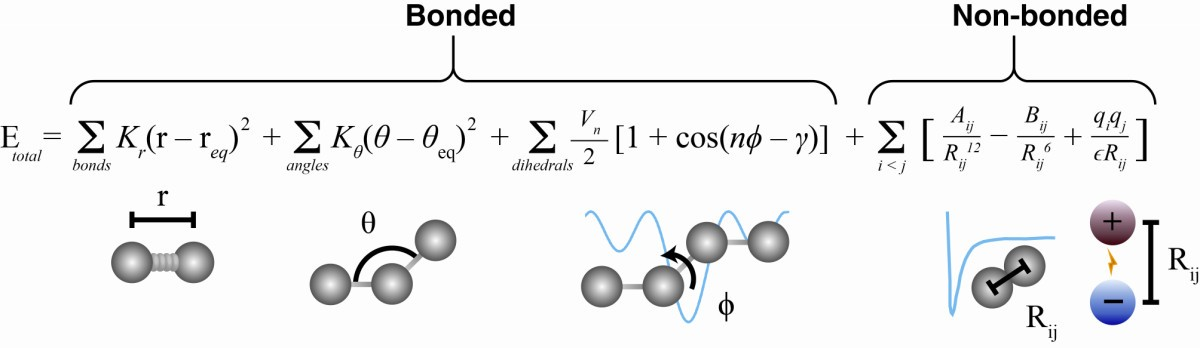

Um campo de força clássico escreve a energia potencial como uma soma de termos simples:

$$
U = \underbrace{\sum_\text{ligações} \frac{k_l}{2}(l - l_0)^2 + \sum_\text{ângulos} \frac{k_\theta}{2}(\theta-\theta_0)^2 + \sum_\text{diedros} k_\phi\left[1+\cos(n\phi-\phi_0)\right]}_\text{termos ligantes (intramoleculares)}
+ \underbrace{\sum_{i<j} 4\varepsilon_{ij}\left[\left(\frac{\sigma_{ij}}{r_{ij}}\right)^{12} - \left(\frac{\sigma_{ij}}{r_{ij}}\right)^{6}\right] + \sum_{i<j}\frac{q_i q_j}{4\pi\varepsilon_0 r_{ij}}}_\text{termos não ligantes (Lennard-Jones + Coulomb)}
$$

- O termo de Lennard-Jones é **o mesmo** que vocês implementaram. (Às vezes ele aparece como $A_{ij}/r^{12} - B_{ij}/r^6$, com $A = 4\varepsilon\sigma^{12}$ e $B = 4\varepsilon\sigma^6$.)
- A água tem só 2 ligações e 1 ângulo: **não há diedros**.
- Os termos não ligantes **não** são calculados entre átomos da mesma molécula ligados por 1 ou 2 ligações (pares 1-2 e 1-3). Essas interações já estão "embutidas" nos termos ligantes. Na água, isso exclui **todos** os pares internos.

### O modelo TIP3P

No TIP3P [Jorgensen *et al.*, J. Chem. Phys. **79**, 926 (1983)] cada molécula tem 3 sítios com cargas parciais, e só o oxigênio tem Lennard-Jones:

| Parâmetro | Valor |
|---|---|
| $q_\text{O}$, $q_\text{H}$ | $-0{,}834\,e$, $+0{,}417\,e$ |
| $\sigma_\text{OO}$, $\varepsilon_\text{OO}$ | $0{,}3151$ nm, $0{,}636$ kJ/mol |
| LJ no H | nenhum ($\varepsilon_\text{H} = 0$) |
| $l_0$, $\theta_0$ | $0{,}09572$ nm, $104{,}52°$ |
| $k_l$, $k_\theta$ | $462\,750{,}4$ kJ/(mol nm²), $836{,}8$ kJ/(mol rad²) |

> ⚠️ O TIP3P original é uma molécula **rígida**. As constantes $k_l$ e $k_\theta$ só são usadas quando pedimos explicitamente uma água flexível, como faremos agora para estudar a molécula isolada.

Para ver de [outros modelos de água](https://en.wikipedia.org/wiki/Water_model) (SPC/E, TIP4P/2005, OPC, ...), veja a Parte 4.

In [ ]:
forcefield = app.ForceField("amber14/tip3p.xml")

# Água FLEXÍVEL (rigidWater=False), isolada no vácuo (sem caixa periódica, sem raio de corte)
system_1mol = forcefield.createSystem(topologia_1mol, nonbondedMethod=app.NoCutoff, rigidWater=False)

print("Forças presentes no System:")
for i, f in enumerate(system_1mol.getForces()):
    print(f"  {i}: {type(f).__name__}")

O `System` é o que o integrador realmente "enxerga": massas, vínculos e uma lista de forças. Vamos abrir cada força e ver que o campo de força **é só um conjunto de números**. Note que procuramos as forças pelo **tipo**, e não pela posição na lista (que pode mudar entre versões).

In [ ]:
def pega_forca(system, tipo):
    return next(f for f in system.getForces() if isinstance(f, tipo))

f_lig = pega_forca(system_1mol, mm.HarmonicBondForce)
f_ang = pega_forca(system_1mol, mm.HarmonicAngleForce)
f_nb  = pega_forca(system_1mol, mm.NonbondedForce)

print("Ligações [i, j, l0, k_l]:")
for i in range(f_lig.getNumBonds()):
    print("  ", f_lig.getBondParameters(i))

print("\nÂngulo [i, j, k, theta0, k_theta]:")
for i in range(f_ang.getNumAngles()):
    print("  ", f_ang.getAngleParameters(i))

print("\nNão ligantes [carga, sigma, epsilon]:")
for atomo in topologia_1mol.atoms():
    print(f"   {atomo.name:2s}", f_nb.getParticleParameters(atomo.index))

print("\nExceções (pares excluídos) [i, j, q_i*q_j, sigma, epsilon]:")
for i in range(f_nb.getNumExceptions()):
    print("  ", f_nb.getExceptionParameters(i))

> ❓ **Pergunte-se:** por que todas as exceções têm $q_iq_j = 0$ e $\varepsilon = 0$? O que isso significa para a energia de uma molécula isolada?

## 1.3 Energia em função da geometria

Criamos uma `Simulation` com o **mesmo integrador de Verlet** que vocês programaram. Para cada geometria, colocamos as posições no `Context` e pedimos a energia potencial ao OpenMM. Depois comparamos com a fórmula analítica do termo harmônico.

In [ ]:
simulation_1mol = app.Simulation(topologia_1mol, system_1mol,
                                 mm.VerletIntegrator(1 * unit.femtosecond), plataforma)

def energia_potencial(sim, pos_nm):
    sim.context.setPositions(pos_nm * unit.nanometer)
    estado = sim.context.getState(getEnergy=True)
    return estado.getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)

k_l, l0       = 462750.4, 0.09572                # kJ/(mol nm²), nm
k_th, theta0  = 836.8, 1.82421813418             # kJ/(mol rad²), rad

In [ ]:
# Varredura do comprimento da ligação O–H1 (ângulo e O–H2 fixos no equilíbrio)
ls = np.linspace(0.07, 0.125, 45)                                   # nm
U_lig = [energia_potencial(simulation_1mol, geometria_agua(l1=l)) for l in ls]

# Varredura do ângulo H–O–H (ligações fixas no equilíbrio)
thetas = np.deg2rad(np.linspace(85, 125, 45))                       # rad
U_ang = [energia_potencial(simulation_1mol, geometria_agua(theta=th)) for th in thetas]

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
axs[0].plot(ls * 10, U_lig, "o", ms=4, label="OpenMM")
axs[0].plot(ls * 10, 0.5 * k_l * (ls - l0)**2, "k-", label=r"$\frac{k_l}{2}(l-l_0)^2$")
axs[0].set_xlabel("Distância O–H (Å)")
axs[0].set_ylabel("Energia potencial (kJ/mol)")

axs[1].plot(np.degrees(thetas), U_ang, "o", ms=4, color="C1", label="OpenMM")
axs[1].plot(np.degrees(thetas), 0.5 * k_th * (thetas - theta0)**2, "k-",
            label=r"$\frac{k_\theta}{2}(\theta-\theta_0)^2$")
axs[1].set_xlabel("Ângulo H–O–H (graus)")
for ax in axs:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()

Os pontos do OpenMM caem **exatamente** sobre as parábolas: para uma molécula isolada, só os termos ligantes contribuem (as interações não ligantes internas foram excluídas).

> ❓ Compare as escalas dos dois gráficos. Esticar a ligação em 0,1 Å custa quanto de energia? E abrir o ângulo em 10°? Compare ambos com $k_BT \approx 2{,}5$ kJ/mol a 300 K. Qual dos dois movimentos é mais "duro"?

## 1.4 Minimização de energia

Partindo de uma geometria distorcida, o OpenMM procura o mínimo de $U$ (algoritmo L-BFGS). Atenção: minimizar **não** é fazer dinâmica — é encontrar a configuração de energia mínima, ou seja, a estrutura a $T = 0$.

In [ ]:
pos_ini = geometria_agua(l1=0.100, l2=0.092, theta=np.deg2rad(110.0))
print(f"Antes:  U = {energia_potencial(simulation_1mol, pos_ini):.4f} kJ/mol")
print("        l1 = {:.5f} nm, l2 = {:.5f} nm, θ = {:.2f}°".format(*mede_geometria(pos_ini)))

simulation_1mol.minimizeEnergy()

estado = simulation_1mol.context.getState(getPositions=True, getEnergy=True)
pos_eq = estado.getPositions(asNumpy=True).value_in_unit(unit.nanometer)
print(f"Depois: U = {estado.getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole):.2e} kJ/mol")
print("        l1 = {:.5f} nm, l2 = {:.5f} nm, θ = {:.2f}°".format(*mede_geometria(pos_eq)))

## 1.5 Vibração e a escolha do passo de tempo $\Delta t$

Vocês já viram que o Verlet fica instável se $\Delta t$ for grande demais. Mas *quão grande* é grande demais? A resposta vem do **movimento mais rápido** do sistema. Aqui, ele é o estiramento da ligação O–H.

Tratando a ligação como um oscilador harmônico com massa reduzida $\mu = m_\text{O} m_\text{H}/(m_\text{O}+m_\text{H})$:

$$\omega = \sqrt{\frac{k_l}{\mu}}, \qquad \tau = \frac{2\pi}{\omega}.$$

Para um oscilador harmônico, o Verlet só é estável se $\omega\,\Delta t < 2$. Na prática, para ter boa precisão, usa-se $\Delta t \lesssim \tau/10$.

In [ ]:
m_O, m_H = 15.99943, 1.007947               # g/mol
mu = m_O * m_H / (m_O + m_H)                # g/mol
omega = np.sqrt(k_l / mu)                   # 1/ps  (kJ/mol = g/mol·nm²/ps²!)
tau = 2 * np.pi / omega                     # ps
c_luz = 2.99792458e-2                       # cm/ps

print(f"μ = {mu:.4f} g/mol")
print(f"ω = {omega:.1f} ps⁻¹  →  período τ = {tau*1e3:.2f} fs")
print(f"número de onda = {omega/(2*np.pi*c_luz):.0f} cm⁻¹  (experimental, estiramento O–H: ~3700 cm⁻¹)")
print(f"limite de estabilidade do Verlet: Δt < 2/ω = {2/omega*1e3:.2f} fs")

Vamos verificar isso numericamente: esticamos a ligação O–H1 em 0,1 Å, soltamos a molécula do repouso e integramos as equações de movimento com o `VerletIntegrator` (dinâmica NVE) para diferentes valores de $\Delta t$.

In [ ]:
def vibra(dt_fs, t_total_fs=60.0, l1_inicial=0.10572):
    sim = app.Simulation(topologia_1mol, system_1mol,
                         mm.VerletIntegrator(dt_fs * unit.femtosecond), plataforma)
    sim.context.setPositions(geometria_agua(l1=l1_inicial) * unit.nanometer)
    sim.context.setVelocities(np.zeros((3, 3)) * unit.nanometer / unit.picosecond)
    t, l, E = [], [], []
    for n in range(int(round(t_total_fs / dt_fs)) + 1):
        st = sim.context.getState(getPositions=True, getEnergy=True)
        pos = st.getPositions(asNumpy=True).value_in_unit(unit.nanometer)
        energia = (st.getPotentialEnergy() + st.getKineticEnergy()).value_in_unit(unit.kilojoule_per_mole)
        if not np.isfinite(energia) or energia > 1e3:   # a integração "explodiu"
            break
        t.append(n * dt_fs); l.append(np.linalg.norm(pos[1] - pos[0]) * 10); E.append(energia)
        sim.step(1)
    return np.array(t), np.array(l), np.array(E)

fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
for dt_fs in [0.1, 1.0, 2.0, 3.0]:
    t, l, E = vibra(dt_fs)
    estilo = dict(lw=2) if dt_fs < 0.5 else dict(marker="o", ms=3, lw=0.8)
    axs[0].plot(t, l, label=f"Δt = {dt_fs} fs", **estilo)
    axs[1].plot(t, E, **estilo)
axs[0].set_ylabel("Distância O–H1 (Å)")
axs[0].set_ylim(0.85, 1.10)
axs[1].set_ylabel("Energia total (kJ/mol)")
axs[1].set_ylim(0, 60)
axs[1].set_xlabel("Tempo (fs)")
axs[0].legend(ncol=4, fontsize=8, loc="lower right")
plt.tight_layout()

> ❓ **Observe:**
> - Com $\Delta t = 0{,}1$ fs a curva é suave e a energia total é constante. Qual é o período de oscilação? Ele bate com $\tau$?
> - Com $\Delta t = 1$ e $2$ fs a energia total oscila cada vez mais (e a curva da distância fica "serrilhada"): poucos pontos por período.
> - Com $\Delta t = 3$ fs, acima do limite $2/\omega$, a integração diverge em poucos passos.
>
> *Detalhe técnico:* o `VerletIntegrator` do OpenMM usa a forma *leapfrog*, em que as velocidades ficam meio passo defasadas das posições. Por isso a energia total calculada oscila em torno de um valor constante (sem deriva) mesmo quando a integração é estável.

**Consequência prática:** com a água flexível precisaríamos de $\Delta t \approx 0{,}5$–$1$ fs. Como o TIP3P foi parametrizado como molécula **rígida**, podemos congelar as ligações O–H e o ângulo com **vínculos** (*constraints*; para a água o OpenMM usa o algoritmo SETTLE). O movimento mais rápido passa a ser a libração (rotação "balançante") das moléculas, bem mais lenta, e podemos usar $\Delta t = 2$ fs sem perder precisão. Isso não é uma aproximação adicional: **é o próprio modelo**.

---
# Parte 2 — Uma caixa de água líquida

## 2.1 Parâmetros da simulação

Todos os "botões" da simulação ficam nesta célula. Os tempos são dados em ps e convertidos em número de passos depois.

In [ ]:
N_mol       = 1000                                  # número de moléculas de água
temperatura = 300 * unit.kelvin
pressao     = 1 * unit.bar
rho_inicial = 997 * unit.kilogram / unit.meter**3   # densidade usada só para escolher o tamanho inicial da caixa

dt          = 2 * unit.femtosecond                  # passo de tempo (água rígida!)
gamma       = 1 / unit.picosecond                   # coeficiente de atrito do termostato de Langevin
t_nvt       = 20 * unit.picosecond                  # equilibração NVT
t_npt       = 300 * unit.picosecond                 # simulação NPT

M_agua = 18.01528 * unit.gram / unit.mole           # massa molar da água

## 2.2 Tamanho da caixa

Em vez de chutar o tamanho da caixa, escolhemos $L$ para que a densidade inicial já seja próxima da do líquido:

$$ L = \left(\frac{N\,M}{\rho\,N_A}\right)^{1/3} $$

Lembre também da convenção da imagem mínima: o raio de corte deve ser menor que $L/2$.

In [ ]:
massa_total = N_mol * M_agua / unit.AVOGADRO_CONSTANT_NA
V_inicial = (massa_total / rho_inicial).value_in_unit(unit.nanometer**3)    # nm³
L = V_inicial ** (1 / 3)                                                    # nm

print(f"Volume inicial: {V_inicial:.2f} nm³")
print(f"Aresta da caixa: L = {L:.3f} nm  (L/2 = {L/2:.2f} nm deve ser maior que o raio de corte)")
print(f"Densidade numérica: {N_mol/V_inicial:.2f} moléculas/nm³")

## 2.3 Configuração inicial

Colocamos as moléculas nos sítios de uma rede cúbica simples, cada uma com uma orientação aleatória. Essa configuração é artificial (parece um cristal), mas isso não importa: a equilibração vai "derretê-la" em poucos ps.

A topologia da caixa é simplesmente a de uma molécula repetida `N_mol` vezes, mais a informação da **caixa periódica**.

In [ ]:
def rotacao_aleatoria(rng):
    # Matriz de rotação aleatória uniforme (decomposição QR de uma matriz gaussiana)
    q, r = np.linalg.qr(rng.normal(size=(3, 3)))
    q *= np.sign(np.diag(r))
    if np.linalg.det(q) < 0:
        q[:, 0] *= -1
    return q

def monta_caixa(N_mol, L, semente=2024):
    # Retorna (topologia, posições em nm) de N_mol águas numa caixa cúbica de aresta L (nm)
    rng = np.random.default_rng(semente)
    topologia = app.Topology()
    cadeia = topologia.addChain()
    for i in range(N_mol):
        res = topologia.addResidue("HOH", cadeia)
        O  = topologia.addAtom("O",  elemento_O, res)
        H1 = topologia.addAtom("H1", elemento_H, res)
        H2 = topologia.addAtom("H2", elemento_H, res)
        topologia.addBond(O, H1)
        topologia.addBond(O, H2)
    topologia.setUnitCellDimensions(mm.Vec3(L, L, L) * unit.nanometer)

    molecula = geometria_agua()                    # nm
    molecula -= molecula.mean(axis=0)              # centraliza a molécula na origem
    n_lado = int(np.ceil(N_mol ** (1 / 3)))        # sítios da rede por aresta
    a = L / n_lado                                 # espaçamento da rede (nm)
    posicoes = []
    for idx in np.ndindex(n_lado, n_lado, n_lado):
        if len(posicoes) == N_mol:
            break
        centro = (np.array(idx) + 0.5) * a
        posicoes.append(centro + molecula @ rotacao_aleatoria(rng).T)
    return topologia, np.vstack(posicoes)

topologia, posicoes = monta_caixa(N_mol, L)
print(topologia)
print("Formato do array de posições:", posicoes.shape, "(em nm)")

with open("agua_inicial.pdb", "w") as arq:
    app.PDBFile.writeFile(topologia, posicoes * unit.nanometer, arq)

## 2.4 O `System` para o líquido

Três diferenças importantes em relação à molécula isolada:

1. **`nonbondedMethod=app.PME`** — com condições periódicas, a interação de Coulomb ($\propto 1/r$) decai lentamente demais para ser simplesmente cortada. O *Particle Mesh Ewald* separa a soma em uma parte de curto alcance (calculada até o raio de corte, como no seu código de LJ) e uma parte de longo alcance (calculada no espaço recíproco com FFT).
2. **`nonbondedCutoff=1 nm`** — raio de corte do Lennard-Jones e da parte real do PME. O OpenMM adiciona por padrão uma **correção de longo alcance** para a dispersão do LJ, importante para obter a densidade correta.
3. **`rigidWater=True`** — moléculas rígidas (SETTLE), o que permite $\Delta t = 2$ fs.

In [ ]:
system = forcefield.createSystem(topologia,
                                 nonbondedMethod=app.PME,
                                 nonbondedCutoff=1.0 * unit.nanometer,
                                 constraints=app.HBonds,
                                 rigidWater=True)

n_atomos = system.getNumParticles()
n_vinculos = system.getNumConstraints()
n_gl = 3 * n_atomos - n_vinculos - 3     # graus de liberdade (–3: momento total removido)

print("Forças:", [type(f).__name__ for f in system.getForces()])
print(f"Átomos: {n_atomos},  vínculos: {n_vinculos}  ({n_vinculos//N_mol} por molécula)")
print(f"Graus de liberdade: {n_gl}  (≈ 6 por molécula: 3 de translação + 3 de rotação)")
print("Correção de longo alcance do LJ:", pega_forca(system, mm.NonbondedForce).getUseDispersionCorrection())

## 2.5 Integrador, minimização e velocidades iniciais

O `LangevinMiddleIntegrator` resolve a **mesma equação de Langevin** que vocês implementaram,

$$ m_i\,\ddot{\mathbf r}_i = \mathbf F_i - \gamma\, m_i\,\dot{\mathbf r}_i + \sqrt{2\gamma\, m_i k_B T}\;\boldsymbol\eta_i(t), $$

com um esquema de integração mais preciso. O atrito $\gamma$ e o ruído $\boldsymbol\eta$ fazem o papel de **termostato** (ensemble NVT).

Antes de começar a dinâmica, minimizamos a energia (para remover sobreposições da configuração inicial) e sorteamos velocidades da distribuição de Maxwell–Boltzmann.

In [ ]:
integrator = mm.LangevinMiddleIntegrator(temperatura, gamma, dt)
simulation = app.Simulation(topologia, system, integrator, plataforma)
simulation.context.setPositions(posicoes * unit.nanometer)

def U_por_molecula(sim):
    U = sim.context.getState(getEnergy=True).getPotentialEnergy()
    return U.value_in_unit(unit.kilojoule_per_mole) / N_mol

print(f"U/N antes da minimização:  {U_por_molecula(simulation):9.2f} kJ/mol")
simulation.minimizeEnergy()
print(f"U/N depois da minimização: {U_por_molecula(simulation):9.2f} kJ/mol")

simulation.context.setVelocitiesToTemperature(temperatura, 2024)

## 2.6 *Reporters*: o que salvar e com que frequência

Os *reporters* são chamados automaticamente durante `simulation.step()`, substituindo as listas onde vocês guardavam energia e temperatura.

- `DCDReporter`: salva as **posições** (a trajetória) para análise estrutural. É um arquivo grande, então salvamos com menos frequência.
- `StateDataReporter`: salva grandezas termodinâmicas (energia, $T$, $V$, densidade) em um arquivo CSV.

In [ ]:
passos_nvt = int(round(t_nvt / dt))
passos_npt = int(round(t_npt / dt))
intervalo_log  = 50      # passos  → a cada 0,1 ps
intervalo_traj = 500     # passos  → a cada 1 ps

print(f"NVT: {passos_nvt} passos;  NPT: {passos_npt} passos")

simulation.reporters = []   # limpa reporters antigos, caso a célula seja executada de novo
simulation.reporters.append(app.DCDReporter("agua.dcd", intervalo_traj))
simulation.reporters.append(app.StateDataReporter(
    "agua_log.csv", intervalo_log, step=True, time=True,
    potentialEnergy=True, kineticEnergy=True, totalEnergy=True,
    temperature=True, volume=True, density=True))
simulation.reporters.append(app.StateDataReporter(
    stdout, 5000, step=True, time=True, temperature=True, density=True,
    progress=True, remainingTime=True, speed=True, totalSteps=passos_nvt + passos_npt))

## 2.7 Equilibração NVT

Primeiro equilibramos a **volume fixo**: a configuração inicial é artificial e teria uma pressão instantânea enorme. Ligar o barostato logo de cara poderia provocar variações bruscas do volume da caixa.

In [ ]:
print("Equilibrando em NVT...")
simulation.step(passos_nvt)

## 2.8 Simulação NPT

Para controlar a pressão adicionamos um `MonteCarloBarostat`. A cada 25 passos ele:

1. propõe uma pequena variação aleatória do volume $V \to V' = V + \Delta V$, reescalando as posições dos **centros de massa** das moléculas (as moléculas não se deformam);
2. aceita ou rejeita a proposta com o critério de Metropolis, usando
$$\Delta W = \Delta U + P\,\Delta V - N k_B T \ln\frac{V'}{V}.$$

O resultado é uma amostragem do ensemble **NPT**. Como o barostato é uma nova força, precisamos reinicializar o `Context`, preservando posições e velocidades.

In [ ]:
system.addForce(mm.MonteCarloBarostat(pressao, temperatura, 25))
simulation.context.reinitialize(preserveState=True)

print("Simulando em NPT...")
simulation.step(passos_npt)

# Salva a configuração final, com as moléculas "dobradas" para dentro da caixa
estado = simulation.context.getState(getPositions=True, enforcePeriodicBox=True)
topologia.setPeriodicBoxVectors(estado.getPeriodicBoxVectors())
with open("agua_final.pdb", "w") as arq:
    app.PDBFile.writeFile(topologia, estado.getPositions(), arq)

# Apagar a simulação fecha os arquivos dos reporters (necessário no Windows antes de lê-los)
del simulation

---
# Parte 3 — Análise dos resultados

## 3.1 Séries temporais

In [ ]:
df = pd.read_csv("agua_log.csv")
df.head()

A densidade de massa vem diretamente do volume da caixa: $\rho = \dfrac{N M}{N_A V}$. Calculamos à mão e conferimos com a coluna que o próprio OpenMM escreveu:

In [ ]:
NA = 6.02214076e23
massa_kg = N_mol * 18.01528e-3 / NA                   # kg
df["rho (kg/m3)"] = massa_kg / (df["Box Volume (nm^3)"] * 1e-27)
df["U/N (kJ/mol)"] = df["Potential Energy (kJ/mole)"] / N_mol

print("Maior diferença em relação ao OpenMM:",
      np.abs(df["rho (kg/m3)"] - 1000 * df["Density (g/mL)"]).max(), "kg/m³")

In [ ]:
t = df["Time (ps)"]
t_nvt_ps = t_nvt.value_in_unit(unit.picosecond)
grandezas = [("U/N (kJ/mol)", r"$U/N$ (kJ/mol)", "C0"), ("Temperature (K)", r"$T$ (K)", "C3"),
             ("Box Volume (nm^3)", r"$V$ (nm³)", "C1"), ("rho (kg/m3)", r"$\rho$ (kg/m³)", "C2")]

fig, axs = plt.subplots(4, 1, figsize=(8, 8), sharex=True)
for ax, (coluna, rotulo, cor) in zip(axs, grandezas):
    ax.plot(t, df[coluna], color=cor, lw=0.7)
    ax.axvline(t_nvt_ps, color="k", ls="--", lw=1)
    ax.set_ylabel(rotulo)
axs[0].text(t_nvt_ps / 2, 0.9, "NVT", transform=axs[0].get_xaxis_transform(), ha="center")
axs[0].text(t_nvt_ps * 1.5, 0.9, "NPT →", transform=axs[0].get_xaxis_transform(), ha="left")
axs[-1].set_xlabel("Tempo (ps)")
plt.tight_layout()

> ❓ **Discuta:**
> - As velocidades iniciais foram sorteadas a 300 K, mas a temperatura logo no início é bem diferente. Olhe a energia potencial no mesmo intervalo: para onde foi a energia? (Dica: teorema da equipartição; a configuração inicial estava num mínimo de energia.)
> - Por que o volume é constante no começo?
> - A partir de que tempo as grandezas parecem flutuar em torno de um valor constante? Esse é o fim da **equilibração**: os dados anteriores **não** devem entrar nas médias.

In [ ]:
t_corte = 50    # ps — ajuste olhando os gráficos acima
prod = df[df["Time (ps)"] > t_corte]
print(f"{len(prod)} amostras entre {t_corte} e {prod['Time (ps)'].max():.0f} ps")

## 3.2 Médias e flutuações

In [ ]:
for coluna, simbolo, unidade in [("U/N (kJ/mol)", "U/N", "kJ/mol"), ("Temperature (K)", "T", "K"),
                                 ("Box Volume (nm^3)", "V", "nm^3"), ("rho (kg/m3)", r"\rho", "kg/m^3")]:
    media, desvio = prod[coluna].mean(), prod[coluna].std()
    display(Math(rf"\langle {simbolo} \rangle = {media:.2f}\ \mathrm{{{unidade}}}, \qquad "
                 rf"\sigma_{{{simbolo}}} = {desvio:.2f}\ \mathrm{{{unidade}}}"))

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3))
for ax, (coluna, rotulo, cor) in zip(axs, [grandezas[0], grandezas[1], grandezas[3]]):
    x = prod[coluna]
    ax.hist(x, bins=50, density=True, color=cor, alpha=0.7)
    grade = np.linspace(x.mean() - 4 * x.std(), x.mean() + 4 * x.std(), 200)
    ax.plot(grade, np.exp(-0.5 * ((grade - x.mean()) / x.std())**2) / np.sqrt(2 * np.pi * x.std()**2), "k-")
    ax.set_xlabel(rotulo)
plt.tight_layout()

As distribuições são aproximadamente gaussianas, como previsto pela física estatística para um sistema com muitas partículas. A largura dessas gaussianas **não é um erro**: é uma propriedade física do ensemble (veja a seção 3.4).

**<span style="color:#A03;font-size:14pt">
&#x270B; HANDS-ON! &#x1F528;
</span>**

> Calcule a densidade da água a $T = 300$ K e $P = 1$ bar e compare com o valor do NIST: $55\,315$ mol/m³ ($\approx 996{,}5$ kg/m³).

## 3.3 Qual é a incerteza da densidade média? ⚠️

É tentador usar o desvio padrão $\sigma_\rho$ como "incerteza". Mas $\sigma_\rho$ mede o quanto a densidade **flutua** de um instante para outro, e não quão bem conhecemos a **média** $\langle\rho\rangle$.

Se as $n$ amostras fossem independentes, o erro da média seria $\sigma/\sqrt{n}$. Mas amostras salvas a cada 0,1 ps são fortemente **correlacionadas**: o volume não muda muito em 0,1 ps. Usar $\sigma/\sqrt{n}$ diretamente subestimaria o erro.

**Média em blocos:** dividimos a série em blocos de duração $\tau_b$, calculamos a média de cada bloco e o erro da média a partir da dispersão dessas médias. Quando os blocos ficam maiores que o tempo de correlação, as médias dos blocos ficam independentes e a estimativa do erro atinge um **platô**.

In [ ]:
def erro_por_blocos(x, tamanho_bloco):
    # Erro da média de x usando blocos de 'tamanho_bloco' amostras
    x = np.asarray(x)
    n_blocos = len(x) // tamanho_bloco
    medias = x[:n_blocos * tamanho_bloco].reshape(n_blocos, tamanho_bloco).mean(axis=1)
    return medias.std(ddof=1) / np.sqrt(n_blocos)

dt_amostra = intervalo_log * dt.value_in_unit(unit.picosecond)     # ps entre amostras
x = prod["rho (kg/m3)"].values
tamanhos = np.unique(np.logspace(0, np.log10(len(x) // 8), 30).astype(int))
erros = [erro_por_blocos(x, b) for b in tamanhos]

plt.figure(figsize=(6, 3.5))
plt.semilogx(tamanhos * dt_amostra, erros, "o-")
plt.axhline(x.std() / np.sqrt(len(x)), color="gray", ls=":", label=r"$\sigma/\sqrt{n}$ (amostras independentes)")
plt.xlabel("Duração do bloco (ps)")
plt.ylabel("Erro da média de ρ (kg/m³)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()

In [ ]:
bloco_ps = 10                                   # escolha um valor no platô do gráfico acima
erro_rho = erro_por_blocos(x, int(bloco_ps / dt_amostra))
n_efetivo = (x.std() / erro_rho)**2

print(f"ρ = {x.mean():.1f} ± {erro_rho:.1f} kg/m³   (flutuação σ = {x.std():.1f} kg/m³)")
print(f"{len(x)} amostras, mas só ≈ {n_efetivo:.0f} amostras efetivamente independentes")

> ❓ A diferença entre a densidade do TIP3P e a experimental é maior ou menor que a incerteza estatística? Se for maior, ela não é ruído: é uma limitação do **modelo** (e de detalhes como o tratamento das interações de longo alcance).

## 3.4 Física estatística a partir das flutuações

As flutuações são informação física. Duas relações clássicas permitem testar a simulação:

**Temperatura.** No ensemble canônico a temperatura instantânea (calculada pela energia cinética) flutua com
$$\frac{\sigma_T}{\langle T\rangle} = \sqrt{\frac{2}{N_\text{gl}}},$$
onde $N_\text{gl}$ é o número de graus de liberdade (calculado na seção 2.4).

**Compressibilidade isotérmica.** No ensemble NPT as flutuações de volume dão
$$\kappa_T = -\frac{1}{V}\left(\frac{\partial V}{\partial P}\right)_T = \frac{\langle V^2\rangle - \langle V\rangle^2}{k_B T\,\langle V\rangle}.$$
O valor experimental para a água a 300 K é $\kappa_T \approx 4{,}5\times10^{-5}$ bar⁻¹.

In [ ]:
kB = 1.380649e-23                   # J/K
T_ref = temperatura.value_in_unit(unit.kelvin)

T = prod["Temperature (K)"]
print(f"σ_T/<T> simulado:   {T.std() / T.mean():.4f}")
print(f"√(2/N_gl) teórico:  {np.sqrt(2 / n_gl):.4f}")

V = prod["Box Volume (nm^3)"].values * 1e-27          # m³
kappa = V.var() / (kB * T_ref * V.mean())             # 1/Pa
print(f"\nκ_T = {kappa * 1e5 * 1e5:.1f} × 10⁻⁵ bar⁻¹   (experimental ≈ 4,5 × 10⁻⁵ bar⁻¹)")

Note uma consequência importante: como $\langle\delta V^2\rangle = k_B T\,\kappa_T \langle V\rangle$ e $\langle V\rangle \propto N$,
$$\frac{\sigma_\rho}{\langle\rho\rangle} = \frac{\sigma_V}{\langle V\rangle} = \sqrt{\frac{k_BT\,\kappa_T}{\langle V\rangle}} \propto \frac{1}{\sqrt N}.$$
As flutuações relativas diminuem com o tamanho do sistema. No limite termodinâmico, $N\to\infty$, elas desaparecem e os ensembles se tornam equivalentes.

> ⚠️ Flutuações (variâncias) convergem bem mais devagar que médias: a incerteza de $\kappa_T$ com algumas centenas de ps é grande. Com que precisão você confia no seu valor?

### Entalpia de vaporização

Para um modelo rígido, a energia potencial de uma molécula isolada no gás é zero. Então a entalpia de vaporização é aproximadamente
$$\Delta H_\text{vap} \approx -\frac{\langle U\rangle}{N} + RT.$$
O TIP3P foi ajustado para reproduzir a densidade e $\Delta H_\text{vap}$ da água a 25 °C (experimental: $\approx 44$ kJ/mol).

In [ ]:
R = 8.314462618e-3                  # kJ/(mol K)
dHvap = -prod["U/N (kJ/mol)"].mean() + R * T_ref
print(f"ΔH_vap ≈ {dHvap:.1f} kJ/mol   (experimental ≈ 44 kJ/mol)")

## 3.5 Estrutura do líquido: função de distribuição radial $g_\text{OO}(r)$

A trajetória (arquivo DCD) guarda as posições. Com o MDTraj calculamos a função de distribuição radial entre oxigênios: a densidade de oxigênios a uma distância $r$ de um oxigênio de referência, dividida pela densidade média.

In [ ]:
import mdtraj as md

traj = md.load("agua.dcd", top="agua_inicial.pdb")
t_quadros = (np.arange(traj.n_frames) + 1) * intervalo_traj * dt.value_in_unit(unit.picosecond)
traj_prod = traj[t_quadros > t_corte]
print(traj_prod)

pares_OO = traj.topology.select_pairs("name O", "name O")
r, g = md.compute_rdf(traj_prod, pares_OO, r_range=(0.0, 1.0), n_bins=200)

In [ ]:
# Número de coordenação: n(r) = 4π ρ_O ∫ g(r') r'² dr'
rho_O = N_mol / traj_prod.unitcell_volumes.mean()          # oxigênios por nm³
dr = r[1] - r[0]
n_coord = 4 * np.pi * rho_O * np.cumsum(g * r**2) * dr

i_pico = np.argmax(g)
janela = (r > r[i_pico]) & (r < 0.40)
i_min = np.where(janela)[0][np.argmin(g[janela])]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(r * 10, g, label=r"$g_{OO}(r)$")
ax.axhline(1, color="gray", lw=0.8)
ax.axvline(r[i_min] * 10, color="gray", ls=":")
ax2 = ax.twinx()
ax2.plot(r * 10, n_coord, "C1--", label="n(r)")
ax2.set_ylim(0, 12); ax2.set_ylabel("Número de coordenação n(r)", color="C1")
ax.set_xlabel("r (Å)"); ax.set_ylabel(r"$g_{OO}(r)$")
plt.tight_layout()

print(f"1º pico: r = {r[i_pico]*10:.2f} Å  (experimental ≈ 2,8 Å)")
print(f"1º mínimo: r = {r[i_min]*10:.2f} Å  →  número de coordenação ≈ {n_coord[i_min]:.1f}")

> ❓ **Discuta:**
> - Por que $g(r) = 0$ para $r \lesssim 2{,}4$ Å? E por que $g(r)\to 1$ para $r$ grande?
> - Numa rede tetraédrica perfeita (gelo) cada molécula tem 4 vizinhas; num líquido simples, como o de Lennard-Jones que vocês simularam, são ≈ 12. Onde fica o TIP3P? O que isso diz sobre a estrutura da água líquida?
> - Na água real há um segundo pico em ≈ 4,5 Å ($\approx 1{,}63 \times 2{,}8$ Å, a razão de distâncias de um tetraedro). Ele aparece claramente na sua simulação? O TIP3P é conhecido por ter uma estrutura tetraédrica pouco marcada.

### (Opcional) Visualizando a caixa

In [ ]:
try:
    import py3Dmol
except ImportError:
    !pip install -q py3Dmol
    import py3Dmol

vis = py3Dmol.view(width=500, height=450)
vis.addModel(open("agua_final.pdb").read(), "pdb")
vis.setStyle({"stick": {"radius": 0.12}, "sphere": {"scale": 0.22}})
vis.addUnitCell()
vis.zoomTo()
vis.show()

---
# Parte 4 — Hands-on

Para os exercícios, juntamos tudo o que foi feito nas Partes 2 e 3 em duas funções.

In [ ]:
def simula_agua(N_mol=1000, temperatura=300*unit.kelvin, pressao=1*unit.bar,
                t_nvt=20*unit.picosecond, t_npt=300*unit.picosecond, dt=2*unit.femtosecond,
                forcefield=app.ForceField("amber14/tip3p.xml"), prefixo="agua", intervalo_log=50):
    # Monta, equilibra (NVT) e simula (NPT) uma caixa de água. Retorna o nome do arquivo CSV.
    massa = N_mol * 18.01528 * unit.gram / unit.mole / unit.AVOGADRO_CONSTANT_NA
    L = ((massa / (997 * unit.kilogram / unit.meter**3)).value_in_unit(unit.nanometer**3)) ** (1 / 3)
    topologia, posicoes = monta_caixa(N_mol, L)

    system = forcefield.createSystem(topologia, nonbondedMethod=app.PME,
                                     nonbondedCutoff=1.0*unit.nanometer, constraints=app.HBonds,
                                     rigidWater=True)
    integrator = mm.LangevinMiddleIntegrator(temperatura, 1/unit.picosecond, dt)
    simulation = app.Simulation(topologia, system, integrator, plataforma)
    simulation.context.setPositions(posicoes * unit.nanometer)
    simulation.minimizeEnergy()
    simulation.context.setVelocitiesToTemperature(temperatura)

    passos_nvt, passos_npt = int(round(t_nvt / dt)), int(round(t_npt / dt))
    arquivo = f"{prefixo}_log.csv"
    simulation.reporters.append(app.StateDataReporter(
        arquivo, intervalo_log, step=True, time=True, potentialEnergy=True, temperature=True, volume=True))
    simulation.reporters.append(app.StateDataReporter(
        stdout, 10000, step=True, density=True, progress=True, remainingTime=True,
        totalSteps=passos_nvt + passos_npt))

    simulation.step(passos_nvt)
    system.addForce(mm.MonteCarloBarostat(pressao, temperatura, 25))
    simulation.context.reinitialize(preserveState=True)
    simulation.step(passos_npt)
    del simulation
    return arquivo


def analisa(arquivo, N_mol, temperatura=300*unit.kelvin, t_corte=50, bloco_ps=10):
    # Densidade média (kg/m³), flutuação, erro da média (blocos) e compressibilidade
    df = pd.read_csv(arquivo)
    df = df[df["Time (ps)"] > t_corte]
    V = df["Box Volume (nm^3)"].values * 1e-27                         # m³
    rho = N_mol * 18.01528e-3 / 6.02214076e23 / V                      # kg/m³
    dt_amostra = df["Time (ps)"].diff().median()
    T = temperatura.value_in_unit(unit.kelvin)
    return {"N": N_mol,
            "rho": rho.mean(),
            "flutuacao": rho.std(),
            "erro_media": erro_por_blocos(rho, max(1, int(bloco_ps / dt_amostra))),
            "kappa_T (1e-5/bar)": V.var() / (1.380649e-23 * T * V.mean()) * 1e10,
            "U/N": df["Potential Energy (kJ/mole)"].mean() / N_mol}

**<span style="color:#A03;font-size:14pt">
&#x270B; HANDS-ON 1: tempo de simulação &#x1F528;
</span>**

> Repita a simulação com as mesmas 1000 moléculas, mas com 600 ps de NPT. Compare com a simulação de 300 ps:
> - A **flutuação** $\sigma_\rho$ mudou?
> - O **erro da média** mudou? Por qual fator você esperaria que ele mudasse?

**<span style="color:#A03;font-size:14pt">
&#x270B; HANDS-ON 2: tamanho do sistema &#x1F528;
</span>**

> Os dados abaixo foram obtidos com caixas de 500 a 5000 moléculas. A coluna `sigma` é o desvio padrão da densidade instantânea.
> - Mostre que $\sigma_\rho \propto N^{-1/2}$.
> - Calcule $\kappa_T$ para cada $N$. Ele depende de $N$?
> - Por que a "barra de erro" desse gráfico **não** é a incerteza da densidade média?

In [ ]:
N_dados     = np.array([500, 1000, 2000, 3000, 4000, 5000])
n_dados     = np.array([54929.37, 55151.03, 55086.23, 55022.79, 55071.59, 55035.42])   # mol/m³
sigma_dados = np.array([659.29, 479.79, 320.27, 266.33, 235.66, 226.33])                # mol/m³

plt.figure(figsize=(6, 4))
plt.errorbar(N_dados, n_dados, yerr=sigma_dados, fmt="o", capsize=5, label="TIP3P (média ± σ)")
plt.axhline(55315, color="k", ls="--", label="Experimental (NIST)")
plt.xlabel("Número de moléculas"); plt.ylabel("Densidade (mol/m³)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()

**<span style="color:#A03;font-size:14pt">
&#x270B; HANDS-ON 3: dependência com a temperatura &#x1F528;
</span>**

> Simule a água a 280, 320 e 350 K (1 bar). Busque as densidades experimentais no [NIST Chemistry WebBook](https://webbook.nist.gov/chemistry/fluid/) e faça um gráfico $\rho \times T$ comparando o TIP3P com o experimento.
> - O modelo captura a tendência? E a magnitude da expansão térmica?
> - A água real tem um máximo de densidade a 4 °C. Você esperaria que o TIP3P o reproduzisse?

**<span style="color:#A03;font-size:14pt">
&#x270B; DESAFIO: outro modelo de água &#x1F528;
</span>**

> Na prática, ninguém monta a caixa à mão: usa-se o `Modeller`, que já sabe preencher uma caixa com água equilibrada. Use-o para simular o modelo **TIP4P-Ew**, que tem um 4º sítio sem massa (sítio virtual M) carregando a carga negativa. Compare a densidade, $\Delta H_\text{vap}$ e o $g_\text{OO}(r)$ com o TIP3P.

In [ ]:
ff_tip4p = app.ForceField("amber14/tip4pew.xml")
modeller = app.Modeller(app.Topology(), [])
modeller.addSolvent(ff_tip4p, model="tip4pew", boxSize=mm.Vec3(3.1, 3.1, 3.1) * unit.nanometer)
print(modeller.topology)
# Complete: crie o System com PME, o integrador de Langevin e a Simulation (use modeller.topology
# e modeller.positions), equilibre em NVT, ligue o barostato e simule em NPT.

---
## 📌 Resumo

- O OpenMM separa **o que** é simulado (`Topology` + `ForceField` → `System`) de **como** é simulado (`Integrator`, `Platform`), e reúne tudo numa `Simulation`.
- Um campo de força é só um conjunto de funções simples e parâmetros. No TIP3P: cargas parciais, um único sítio LJ no oxigênio e geometria rígida.
- O passo de tempo é limitado pelo movimento mais rápido. Vínculos (SETTLE) eliminam as vibrações O–H e permitem $\Delta t = 2$ fs.
- Uma simulação tem **equilibração** (descartada) e **produção** (usada nas médias).
- **Flutuação ≠ incerteza:** o desvio padrão mede uma propriedade física do ensemble ($\propto N^{-1/2}$). O erro da média depende do tempo de simulação e das correlações temporais (média em blocos).
- Das flutuações tiramos propriedades termodinâmicas ($\kappa_T$). Da trajetória, a estrutura ($g(r)$).

### Para saber mais
- [OpenMM User Guide](http://docs.openmm.org/latest/userguide/)
- [OpenMM Cookbook](https://openmm.github.io/openmm-cookbook/)
- [MDTraj](https://www.mdtraj.org/)